## Project Template

In [1]:
from pyspark.sql.functions import explode
from pyspark.sql.functions import split

from pyspark.context import SparkContext
from pyspark.conf import SparkConf
from pyspark.sql.session import SparkSession
from pyspark.sql.functions import col

spark = SparkSession.builder \
    .appName("MyApp") \
    .config("spark.jars.packages", 'org.apache.spark:spark-sql-kafka-0-10_2.12:3.0.0') \
    .config("spark.sql.repl.eagerEval.enabled", True) \
    .getOrCreate()


:: loading settings :: url = jar:file:/usr/local/lib/python3.12/dist-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /root/.ivy2/cache
The jars for the packages stored in: /root/.ivy2/jars
org.apache.spark#spark-sql-kafka-0-10_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-d1661b33-f991-4601-8e59-003844342a5b;1.0
	confs: [default]
	found org.apache.spark#spark-sql-kafka-0-10_2.12;3.0.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.12;3.0.0 in central
	found org.apache.kafka#kafka-clients;2.4.1 in central
	found com.github.luben#zstd-jni;1.4.4-3 in central
	found org.lz4#lz4-java;1.7.1 in central
	found org.xerial.snappy#snappy-java;1.1.7.5 in central
	found org.slf4j#slf4j-api;1.7.30 in central
	found org.spark-project.spark#unused;1.0.0 in central
	found org.apache.commons#commons-pool2;2.6.2 in central
:: resolution report :: resolve 691ms :: artifacts dl 17ms
	:: modules in use:
	com.github.luben#zstd-jni;1.4.4-3 from central in [default]
	org.apache.commons#commons-pool2;2.6.2 from central in [default]


In [2]:
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType, BooleanType, TimestampType, DateType

schema = StructType(
      [
        StructField("name", StringType(), False),
        StructField("price", DoubleType(), False),
        StructField("volume", DoubleType(), False),
        StructField("timestamp", TimestampType(), False),
      ]
    )

In [3]:
kafka_server = "kafka1:9092"   
from pyspark.sql.functions import from_json
from pyspark.sql.functions import to_timestamp

lines = (spark.readStream                        # Get the DataStreamReader
  .format("kafka")                                 # Specify the source format as "kafka"
  .option("kafka.bootstrap.servers", kafka_server) # Configure the Kafka server name and port
  .option("subscribe", "stock")                       # Subscribe to the "en" Kafka topic 
  .option("startingOffsets", "earliest")           # The start point when a query is started
  .option("maxOffsetsPerTrigger", 100)             # Rate limit on max offsets per trigger interval
  .load()
  .select(from_json(col("value").cast("string"), schema).alias("parsed_value"))
# Load the DataFrame
)
df = lines.select("parsed_value.*")

## The assignment starts here

In [4]:
df.printSchema()

root
 |-- name: string (nullable = true)
 |-- price: double (nullable = true)
 |-- volume: double (nullable = true)
 |-- timestamp: timestamp (nullable = true)



25/11/23 14:37:13 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


In [5]:
preview = (
    df.writeStream
    .format("console")
    .outputMode("append")  
    .option("truncate", False)
    .option("numRows", 20) 
    .start()
)

25/11/23 14:37:15 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-78b3a2e9-cff5-4a38-a97a-7f0a4f016968. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 14:37:15 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
                                                                                

-------------------------------------------
Batch: 0
-------------------------------------------
+----+--------+-----------+-------------------+
|name|price   |volume     |timestamp          |
+----+--------+-----------+-------------------+
|ISRG|192.6465|770940.0   |2025-11-23 04:28:31|
|BBT |30.8    |2331836.0  |2025-11-23 04:28:32|
|FITB|16.63   |8284724.0  |2025-11-23 04:28:32|
|ZION|24.57   |2603143.0  |2025-11-23 04:28:33|
|HCP |47.08   |1910622.0  |2025-11-23 04:28:33|
|LLY |53.91   |1.9666635E7|2025-11-23 04:28:34|
|MAC |62.01   |1235821.0  |2025-11-23 04:28:34|
|ADBE|39.15   |2490936.0  |2025-11-23 04:28:35|
|AZO |384.01  |537986.0   |2025-11-23 04:28:35|
|CL  |54.165  |3292340.0  |2025-11-23 04:28:36|
|PPG |69.885  |7626192.0  |2025-11-23 04:28:36|
|KMB |90.08   |1889876.0  |2025-11-23 04:28:37|
|AMAT|13.99   |2.0124979E7|2025-11-23 04:28:37|
|KR  |14.205  |8497132.0  |2025-11-23 04:28:38|
|WEC |39.9    |1573179.0  |2025-11-23 04:28:38|
|VRTX|46.46   |1347794.0  |2025-11-23 0

In [ ]:
# !pip install matplotlib seaborn
!pip install --break-system-packages matplotlib seaborn

In [313]:
from pyspark.sql.functions import window, variance, col, first, last, count, when, expr, lit, collect_list, struct, sum as spark_sum

In [38]:
# Imports for visualizations

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

In [ ]:
preview.stop()

### Task One - The stocks that had the smallest daily variance

**Variance:** It measures how far the numbers are spread out from their average value.

Low variance means stable stock  
High variance means volatile stock  

To find the stocks with the smallest daily variance, we have defined a tumbling window of **10 minutes** which represents a whole day.

We also set **watermark of 1 minute**. A watermark tells Spark how long it should wait for late data before finalizing a window.
Watermarks help us to let spark know when a window is complete.

In [11]:
smallest_daily_variance = (
    df
    .withWatermark("timestamp", "1 minute")
    .groupBy(
        window(col("timestamp"), "10 minutes"),
        col("name")
    )
    .agg(
        variance("price").alias("price_variance")
    )
    .orderBy("price_variance")
)

In [12]:
stream_for_smallest_daily_variance = (
    smallest_daily_variance
    .writeStream
    .format("memory") # Used to write the streaming results into an in-memory Spark SQL table for visualizations
    .queryName("smallest_variance_table") # Gives a name to the streaming query
    .outputMode("complete") # Output the entire table of results
    .option("truncate", False) # No truncation in output values
    .start()
)

25/11/23 14:39:26 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-e08195ed-1f27-49d2-8064-debbfe6c3102. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 14:39:26 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
[Stage 146:==========>                                           (40 + 4) / 200]

In [40]:
spark.sql("""
    SELECT
        window,
        name,
        format_number(price_variance, 6) AS price_variance
    FROM smallest_variance_table
    WHERE price_variance IS NOT NULL
    ORDER BY price_variance
""").show(20, False)

# Displaying the top 20 rows from the table we created in memory during the query
# Displaying only 6 decimal places for price_variance column to make the table presentable
# Ignoring rows where price_variance is NULL
# Displayed in ascending order: stocks with the smallest variance come first

+------------------------------------------+----+--------------+
|window                                    |name|price_variance|
+------------------------------------------+----+--------------+
|{2025-11-23 04:50:00, 2025-11-23 05:00:00}|SYF |0.000000      |
|{2025-11-23 13:10:00, 2025-11-23 13:20:00}|XLNX|0.000000      |
|{2025-11-23 13:20:00, 2025-11-23 13:30:00}|C   |0.000000      |
|{2025-11-23 13:10:00, 2025-11-23 13:20:00}|PPL |0.000050      |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|L   |0.000200      |
|{2025-11-23 04:50:00, 2025-11-23 05:00:00}|PDCO|0.000200      |
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|SYY |0.000450      |
|{2025-11-23 13:10:00, 2025-11-23 13:20:00}|LUK |0.001250      |
|{2025-11-23 04:20:00, 2025-11-23 04:30:00}|FLS |0.002224      |
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|TROW|0.004050      |
|{2025-11-23 04:50:00, 2025-11-23 05:00:00}|MAR |0.005000      |
|{2025-11-23 13:10:00, 2025-11-23 13:20:00}|NTAP|0.006050      |
|{2025-11-23 04:30:00, 20

In [22]:
stream_for_smallest_daily_variance.stop() # Stoping the query after getting enough data for determining stocks with smallest variance - waited for almost 200 stages to be completed

#### Visualization

In [42]:
# Converting Spark table to Pandas DataFrame
top_20_stocks = spark.sql("""
    SELECT
        name,
        price_variance
    FROM smallest_variance_table
    WHERE price_variance IS NOT NULL
    ORDER BY price_variance
    LIMIT 20
""").toPandas()

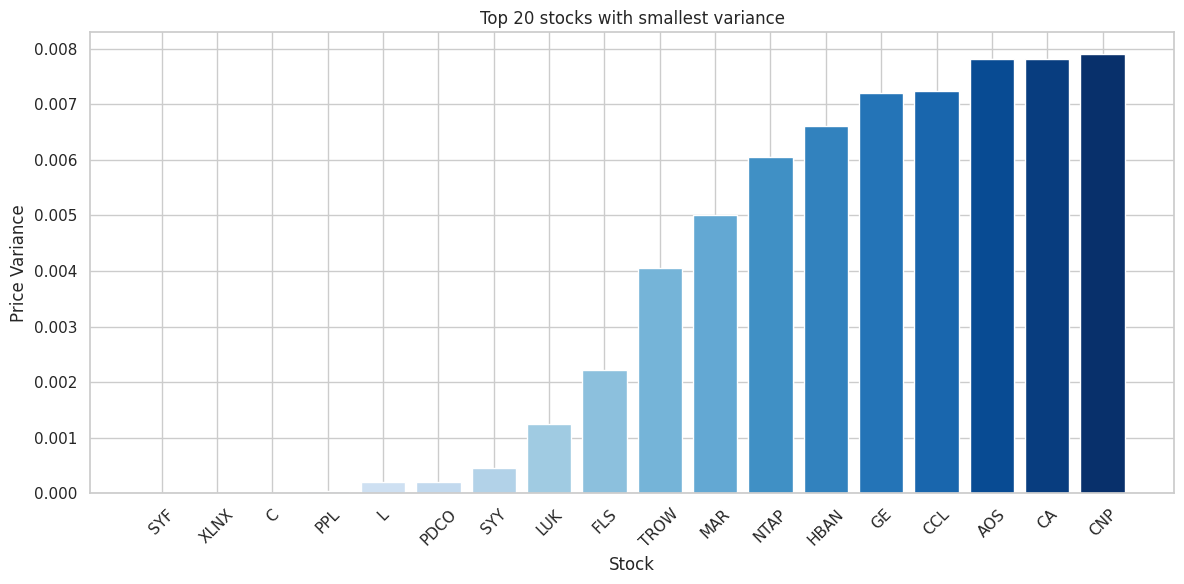

In [44]:
plt.figure(figsize=(12,6))

# Create a color list using a colormap
colors = plt.cm.Blues(np.linspace(0, 1, len(top_20_stocks)))

plt.bar(top_20_stocks["name"], top_20_stocks["price_variance"], color=colors)
plt.xlabel("Stock")
plt.ylabel("Price Variance")
plt.title("Top 20 stocks with smallest variance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

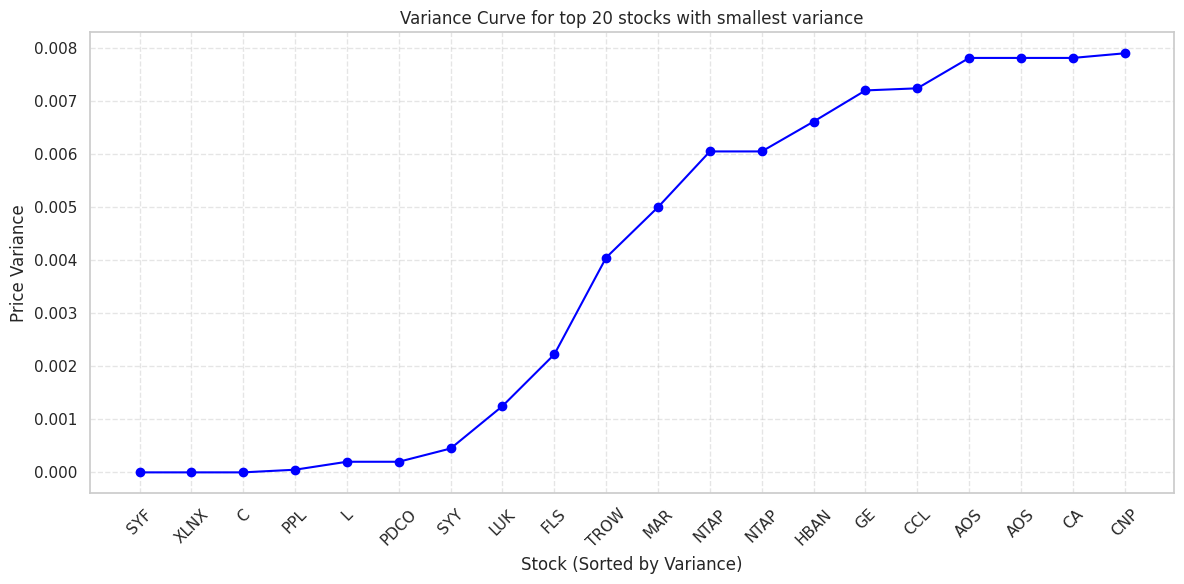

In [53]:
plt.figure(figsize=(12,6))

# Sort by variance to make a smooth curve
sorted_df = top_20_stocks.sort_values("price_variance")

plt.plot(
    range(len(sorted_df)),
    sorted_df["price_variance"],
    marker='o',
    linestyle='-',
    color='blue'
)

plt.xticks(
    range(len(sorted_df)),
    sorted_df["name"],
    rotation=45
)

plt.xlabel("Stock (Sorted by Variance)")
plt.ylabel("Price Variance")
plt.title("Variance Curve for top 20 stocks with smallest variance")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

_______________________________________________________________________________________________________________________________________________________________

### Task Two - Stocks that gained the most every hour and every day

#### Hourly Gain

The hourly gain calculation uses a real **60 minute** tumbling window with watermark of **5 minutes**  
For each stock, we compute the first and last price inside that hour and compute the gain as:  
**gain = end_price − start_price**

In [112]:
hourly_gains = (
    df
    .withWatermark("timestamp", "5 minutes")
    .groupBy(
        window(col("timestamp"), "60 minutes"),  # 1-hour tumbling window
        col("name")
    )
    .agg(
        first("price").alias("start_price"),     # price at the beginning of the hour
        last("price").alias("end_price")         # price at the end of the hour
    )
    .withColumn("gain", col("end_price") - col("start_price"))
    .orderBy(col("gain").desc())
)

In [113]:
hourly_stream = (
    hourly_gains
    .writeStream
    .format("memory")
    .queryName("hourly_gaining_stocks")
    .outputMode("complete")
    .option("truncate", False)
    .start()
)

25/11/23 16:53:28 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-5d666ff2-f6b3-4106-ae7c-b9953c4513a9. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 16:53:28 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
[Stage 564:=======================>                              (87 + 4) / 200]

In [115]:
spark.sql("""
    SELECT
        window,
        name,
        start_price,
        end_price,
        format_number(gain, 2) AS gain
    FROM hourly_gaining_stocks
    ORDER BY gain DESC
""").show(20, False)

# Displaying the top 20 rows from the table we created in memory during the query
# Displaying only 2 decimal places for gain column to make the table presentable
# Displayed in descending order: stocks with the highest hourly gain come first

[Stage 585:============>(195 + 4) / 200][Stage 587:>                (0 + 0) / 4]

+------------------------------------------+----+-----------+---------+----+
|window                                    |name|start_price|end_price|gain|
+------------------------------------------+----+-----------+---------+----+
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|ECL |84.12      |94.0     |9.88|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|TGT |63.21      |72.655   |9.45|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|EOG |63.53      |72.89    |9.36|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|IT  |48.93      |58.2     |9.27|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|VFC |38.1929    |47.369   |9.18|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|ADP |61.715     |70.49    |8.77|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|SIG |62.35      |70.97    |8.62|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|UAL |26.4       |34.91    |8.51|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|AIZ |42.13      |50.31    |8.18|
|{2025-11-23 04:00:00, 2025-11-23 05:00:00}|KMB |90.08      |98.24    |8.16|

[Stage 589:====================>                                 (76 + 4) / 200]

In [ ]:
hourly_stream.stop()

#### Daily Gain

The daily gain calculation uses a **10 minute** tumbling window to simulate a whole day with watermark of **1 minute** just like task 1

In [126]:
daily_gains = (
    df
    .withWatermark("timestamp", "1 minute")
    .groupBy(
        window(col("timestamp"), "10 minutes"),
        col("name")
    )
    .agg(
        first("price").alias("start_price"),
        last("price").alias("end_price")
    )
    .withColumn("gain", col("end_price") - col("start_price"))
    .orderBy(col("gain").desc())
)

In [127]:
daily_stream = (
    daily_gains
    .writeStream
    .format("memory")
    .queryName("daily_gaining_stocks")
    .outputMode("complete")
    .option("truncate", False)
    .start()
)

25/11/23 17:02:22 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-f8fb0235-3081-4e4d-9bdf-12515233b162. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 17:02:22 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
[Stage 632:=============================================>       (173 + 4) / 200]

In [131]:
spark.sql("""
    SELECT
        window,
        name,
        start_price,
        end_price,
        format_number(gain, 2) AS gain
    FROM daily_gaining_stocks
    ORDER BY gain DESC
""").show(20, False)

# Displaying the top 20 rows from the table we created in memory during the query
# Displaying only 2 decimal places for gain column to make the table presentable
# Displayed in descending order: stocks with the highest daily gain come first

[Stage 678:=========>    (93 + 4) / 138][Stage 679:>                (0 + 0) / 4]

+------------------------------------------+----+-----------+---------+-----+
|window                                    |name|start_price|end_price|gain |
+------------------------------------------+----+-----------+---------+-----+
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|AKAM|35.3099    |45.27    |9.96 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|HRS |52.85      |62.68    |9.83 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ADBE|45.17      |54.675   |9.50 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|EXPD|35.67      |45.0     |9.33 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|CAH |47.52      |56.64    |9.12 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|GD  |79.0       |87.94    |8.94 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|TEL |44.96      |53.65    |8.69 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|CTAS|45.09      |53.53    |8.44 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|DISH|40.95      |49.33    |8.38 |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ISRG|160.6632   |168

[Stage 681:=======================================>             (148 + 4) / 200]

In [ ]:
daily_stream.stop()

_______________________________________________________________________________________________________________________________________________________________

### Task Three - Top 10 most traded symbols daily

#### Without using volume column

For this, we are not using volume column. We measure trading activity by counting how many price updates each stock receives within the daily window.  
Using a **10 minute** tumbling window to simulate a whole day with watermark of **1 minute**

In [151]:
top_traded_daily_count = (
    df
    .withWatermark("timestamp", "1 minute")
    .groupBy(
        window(col("timestamp"), "10 minutes"),
        col("name")
    )
    .agg(
        count("*").alias("trade_count") # Count rows for each name.symbol within a window
    )
    .orderBy(col("trade_count").desc()) # Sort in descending order
)

In [152]:
top_traded_stream = (
    top_traded_daily_count
    .writeStream
    .format("memory")
    .queryName("daily_top_traded_count")
    .outputMode("complete")
    .option("truncate", False)
    .start()
)

25/11/23 17:36:34 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-7bc2971f-86b7-4d17-9f9a-c25764e436bf. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 17:36:34 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
[Stage 735:===========================================>         (163 + 4) / 200]

In [155]:
spark.sql("""
    SELECT window, name, trade_count
    FROM daily_top_traded_count
    ORDER BY trade_count DESC
    LIMIT 20
""").show(20, False)

[Stage 778:============>(188 + 4) / 200][Stage 780:>                (0 + 0) / 4]

+------------------------------------------+----+-----------+
|window                                    |name|trade_count|
+------------------------------------------+----+-----------+
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|VMC |8          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|EMR |7          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|CTAS|7          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ORLY|7          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ORCL|6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|GPC |6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ALK |6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|BXP |6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|NEE |6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|MPC |6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ECL |6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|FRT |6          |
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|SCG |6          |
|{2025-1

[Stage 782:==================>                                   (69 + 4) / 200]

In [ ]:
top_traded_stream.stop()

#### Visualization

In [157]:
top_traded_pdf = spark.sql("""
    SELECT name, trade_count
    FROM daily_top_traded_count
    ORDER BY trade_count DESC
    LIMIT 20
""").toPandas()

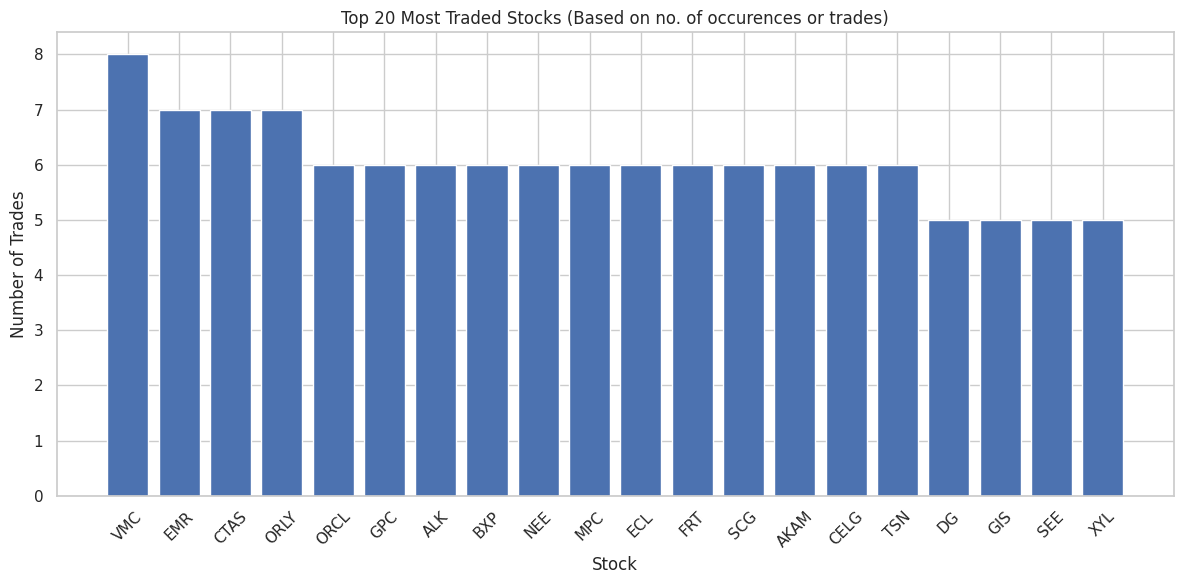

In [159]:
plt.figure(figsize=(12,6))
plt.bar(top_traded_pdf["name"], top_traded_pdf["trade_count"])

plt.xlabel("Stock")
plt.ylabel("Number of Trades")
plt.title("Top 20 Most Traded Stocks (Based on no. of occurences or trades)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Using volume column

This method uses the **volume** column which was added in Kafka producer.  
We use the following formula to find out the stocks with most trades: 
**total_volume = SUM(volume)**

Using a **10 minute** tumbling window to simulate a whole day with watermark of 1 **minute**

In [161]:
top_traded_daily_by_volume = (
    df
    .withWatermark("timestamp", "1 minute")
    .groupBy(
        window(col("timestamp"), "10 minutes"),
        col("name")
    )
    .agg(
        spark_sum("volume").alias("total_volume") # Sum of all volume values for a given stock in window
    )
    .orderBy(col("total_volume").desc())
)

In [162]:
volume_stream = (
    top_traded_daily_by_volume
    .writeStream
    .format("memory")
    .queryName("daily_top_traded_volume")
    .outputMode("complete")
    .option("truncate", False)
    .start()
)

25/11/23 17:51:17 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-888fe8a7-4df3-4db6-ba3c-48dcacf4fd97. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 17:51:17 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
[Stage 825:==============>                                       (54 + 4) / 200]

In [165]:
spark.sql("""
    SELECT 
        window, 
        name, 
        total_volume
    FROM daily_top_traded_volume
    ORDER BY total_volume DESC
    LIMIT 20
""").show(20, False)

[Stage 882:===========> (184 + 4) / 200][Stage 883:>                (0 + 0) / 4]

+------------------------------------------+----+------------+
|window                                    |name|total_volume|
+------------------------------------------+----+------------+
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|AAPL|2.07392904E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|BAC |1.85190506E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ORCL|1.51872883E8|
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|BAC |1.51644829E8|
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|FB  |1.25465774E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|NFLX|1.18112806E8|
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|CSCO|1.15767761E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|MU  |1.13166117E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|C   |1.10511004E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|FB  |1.03573743E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|AAPL|1.01120551E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|MSFT|1.00591002E8|
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|AMD |8.0400

[Stage 885:===============================================>     (179 + 4) / 200]

In [ ]:
volume_stream.stop()

#### Visualization

In [167]:
top_volume = spark.sql("""
    SELECT
        name,
        total_volume
    FROM daily_top_traded_volume
    ORDER BY total_volume DESC
    LIMIT 20
""").toPandas()

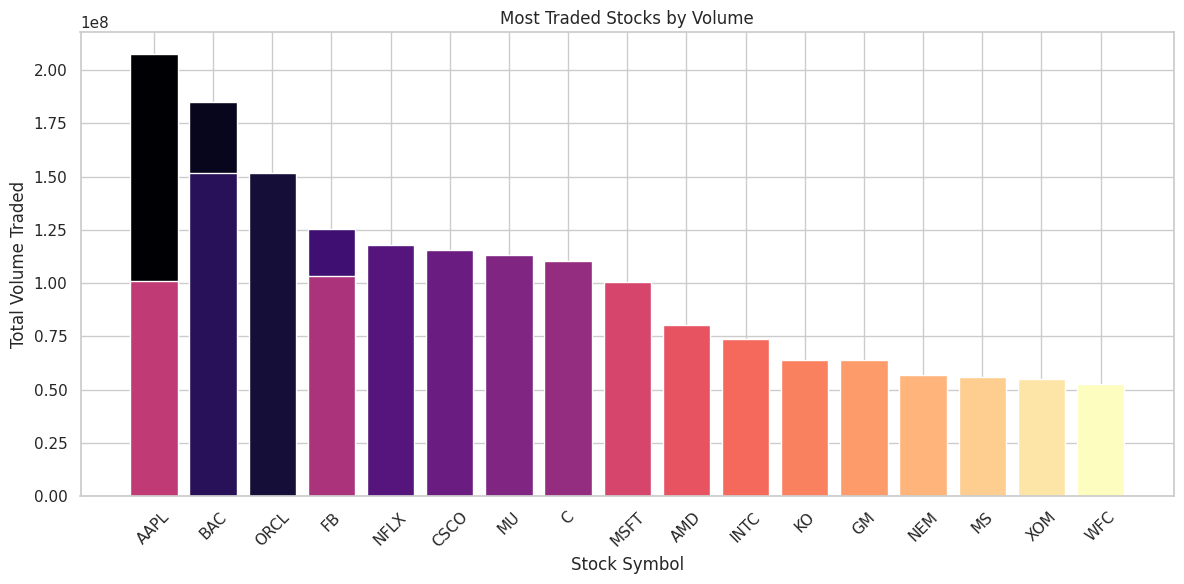

In [172]:
colors = plt.cm.magma(np.linspace(0, 1, len(top_volume)))

plt.figure(figsize=(12,6))
plt.bar(top_volume["name"], top_volume["total_volume"], color=colors)
plt.xlabel("Stock Symbol")
plt.ylabel("Total Volume Traded")
plt.title("Most Traded Stocks by Volume")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

_______________________________________________________________________________________________________________________________________________________________

### Task Four - Top 5 stocks per volume daily

We can use the **volume** column here too like we did in **task 3 - method 2**  
We use the following formula to find out the stocks with most trades: 
**total_volume = SUM(volume)**

Using a **10 minute** tumbling window to simulate a whole day with watermark of **1 minute**

If you consider volume as the number of trades, you can refer to **Task 3 — Method 1**, where we counted the number of rows per stock symbol to identify the most frequently traded stocks.

In [189]:
top_5_traded_daily_by_volume = (
    df
    .withWatermark("timestamp", "1 minute")
    .groupBy(
        window(col("timestamp"), "10 minutes"),
        col("name")
    )
    .agg(
        spark_sum("volume").alias("total_volume") # Sum of all volume values for a given stock in window
    )
    .orderBy(col("total_volume").desc())
)

In [190]:
top_5_volume_stream = (
    top_5_traded_daily_by_volume
    .writeStream
    .format("memory")
    .queryName("daily_5_top_traded_volume")
    .outputMode("complete")
    .option("truncate", False)
    .start()
)

25/11/23 18:21:53 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-552f88b6-f9ba-4a4d-b7dc-5d085710d64d. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 18:21:53 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
[Stage 1000:====>                                                (17 + 4) / 200]

In [202]:
spark.sql("""
    SELECT 
        window, 
        name, 
        total_volume
    FROM daily_5_top_traded_volume
    ORDER BY total_volume DESC
    LIMIT 5
""").show(5, False) #Limit set to 5 since it is requirement of the task

+------------------------------------------+----+------------+
|window                                    |name|total_volume|
+------------------------------------------+----+------------+
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|BAC |1.85190506E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|ORCL|1.51872883E8|
|{2025-11-23 04:40:00, 2025-11-23 04:50:00}|FB  |1.25465774E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|NFLX|1.18112806E8|
|{2025-11-23 04:30:00, 2025-11-23 04:40:00}|MU  |1.13166117E8|
+------------------------------------------+----+------------+



In [ ]:
top_5_volume_stream.stop()

#### Visualization

In [203]:
top5_volume = spark.sql("""
    SELECT 
        name,
        total_volume
    FROM daily_5_top_traded_volume
    ORDER BY total_volume DESC
    LIMIT 5
""").toPandas()

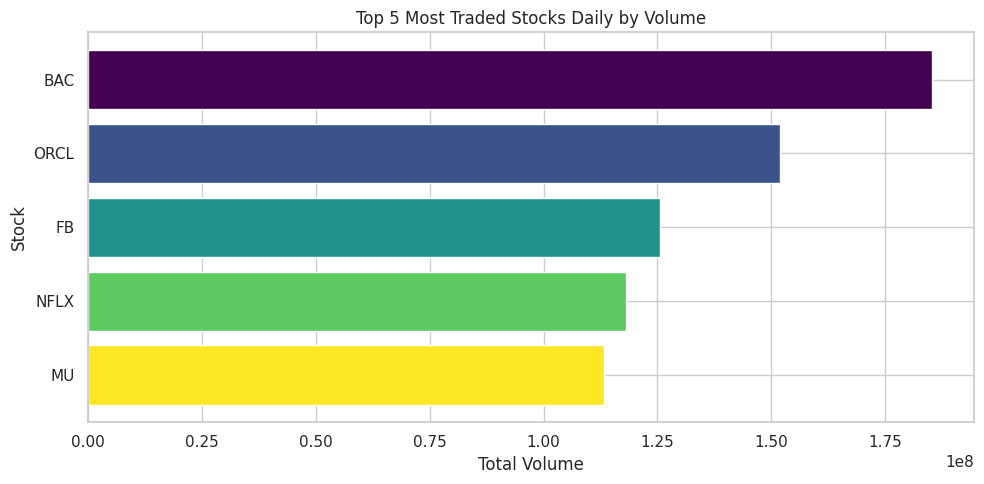

In [209]:
# Generate colors for each bar
colors = plt.cm.viridis(np.linspace(0, 1, len(top5_volume)))

plt.figure(figsize=(10,5))

# Horizontal bar chart with colors + inverted order
plt.barh(
    top5_volume["name"], 
    top5_volume["total_volume"], 
    color=colors
)

plt.title("Top 5 Most Traded Stocks Daily by Volume")
plt.xlabel("Total Volume")
plt.ylabel("Stock")

# Invert so highest volume appears at top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

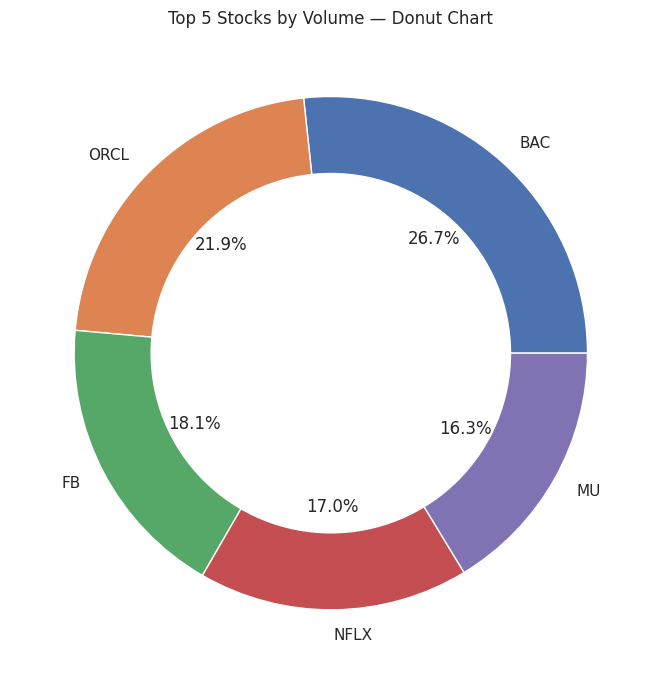

In [210]:
fig, ax = plt.subplots(figsize=(7,7))

ax.pie(
    top5_volume["total_volume"],
    labels=top5_volume["name"],
    autopct="%1.1f%%",
    wedgeprops={'linewidth': 1, 'edgecolor': 'white'}
)

# Create donut hole
centre_circle = plt.Circle((0,0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

plt.title("Top 5 Stocks by Volume — Donut Chart")
plt.tight_layout()
plt.show()

_______________________________________________________________________________________________________________________________________________________________

### Task Five - Design a stop-loss and take profit system. Choose a (or some) stock (s) and test it on it (them).

**Stop-loss:** If the price drops below a certain threshold, immediately sell the stock to prevent further loss.  
**Take-profit:** If the price rises to a target level, automatically sell to secure profits.

**Stocks chosen**  
- DISH  
- PXD  
- CAT

We determine **buy price** as open price in the csv.  
If price drops **5%** below the buy price we signal stop_loss. We calculate this using **stop_price = buy_price * 0.95** (0.95 = 95% of the buy price).  
If price rises **10%** above the buy price we signal take_profit. We calculate this using **take_profit_price = buy_price * 1.10** (1.10 = 110% of the buy price)


In [262]:
selected_stocks = ["DISH", "PXD", "CAT"] # Our chosen stocks

raw_csv = spark.read.csv("stocks.csv", header=False)

buy_price_df = (
    raw_csv
    .select(
        raw_csv["_c6"].alias("name"),   # Stock name
        raw_csv["_c1"].cast("double").alias("price")  # Open price
    )
    .filter(col("name").isin(selected_stocks)) # Keep only the selected stock
    .groupBy("name") # Group by name of stock
    .agg(first("price").alias("buy_price")) #Taking earliest open price available in the CSV for each stock.
)

# Used a static df because it never changes, in case of streaming data it would be impossible to reliably capture first price for stocks

filtered_df = df.filter(col("name").isin(selected_stocks)) # Keeping streaming rows for only selected stocks


In [250]:
live_with_buy = filtered_df.join(buy_price_df, on="name") # Joining the live streaming prices with the static buy price table on the stock name.

In [241]:
signals = (
    live_with_buy
    .withColumn("stop_price", col("buy_price") * 0.95)            # 5% drop threshold
    .withColumn("take_profit_price", col("buy_price") * 1.10)     # 10% gain threshold
    .withColumn(
        "signal",
        when(col("price") <= col("stop_price"), "stop_loss")
        .when(col("price") >= col("take_profit_price"), "take_profit")
        .otherwise("hold")                                       # No action
    )
    .select(
        "timestamp",
        "name",
        "buy_price",
        "stop_price",
        "take_profit_price",
        col("price").alias("current_price"),                     # Renamed for clarity
        "signal"
    )
)

In [242]:
signal_stream = (
    signals
    .writeStream
    .format("memory")
    .queryName("stop_loss_take_profit_signals")
    .outputMode("append")
    .option("truncate", False)
    .start()
)

25/11/23 22:01:49 WARN ResolveWriteToStream: Temporary checkpoint location created which is deleted normally when the query didn't fail: /tmp/temporary-02f0b2a1-2d6f-4665-81a5-6024cd4fcadb. If it's required to delete it under any circumstances, please set spark.sql.streaming.forceDeleteTempCheckpointLocation to true. Important to know deleting temp checkpoint folder is best effort.
25/11/23 22:01:49 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.
                                                                                

In [246]:
spark.sql("""
    SELECT *
    FROM stop_loss_take_profit_signals
    ORDER BY timestamp DESC
""").show(50, False)

+-------------------+----+---------+----------+-----------------+-------------+-----------+
|timestamp          |name|buy_price|stop_price|take_profit_price|current_price|signal     |
+-------------------+----+---------+----------+-----------------+-------------+-----------+
|2025-11-23 13:20:54|PXD |122.17   |116.0615  |134.387          |175.02       |take_profit|
|2025-11-23 13:18:13|DISH|35.23    |33.4685   |38.753           |49.33        |take_profit|
|2025-11-23 13:15:08|DISH|35.23    |33.4685   |38.753           |42.11        |take_profit|
|2025-11-23 13:14:36|CAT |89.47    |84.9965   |98.417           |84.77        |stop_loss  |
|2025-11-23 13:13:39|DISH|35.23    |33.4685   |38.753           |40.95        |take_profit|
|2025-11-23 13:13:16|PXD |122.17   |116.0615  |134.387          |114.075      |stop_loss  |
|2025-11-23 13:12:21|CAT |89.47    |84.9965   |98.417           |89.55        |hold       |
|2025-11-23 13:12:08|PXD |122.17   |116.0615  |134.387          |128.0        |h

[Stage 1421:================================>                   (124 + 4) / 200]

In [ ]:
signal_stream.stop()

#### Visualization

In [252]:
pdf = spark.sql("""
    SELECT timestamp, name, buy_price, stop_price, take_profit_price, current_price, signal
    FROM stop_loss_take_profit_signals
""").toPandas()

pdf['timestamp'] = pd.to_datetime(pdf['timestamp'])

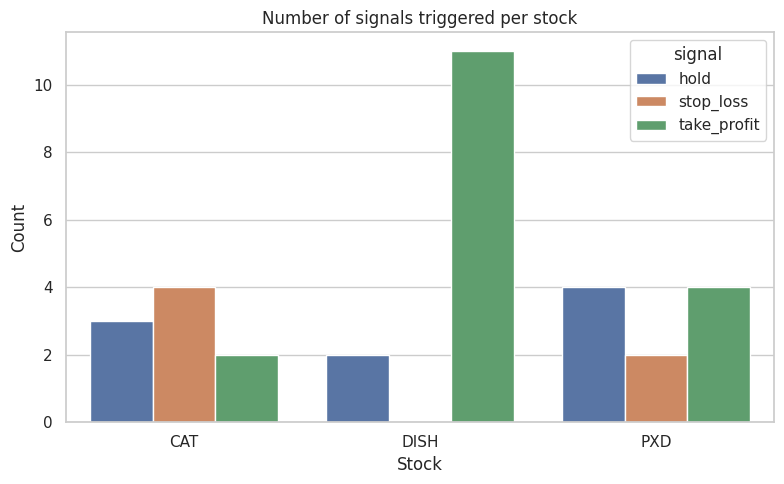

In [255]:
signal_counts = pdf.groupby(["name", "signal"]).size().reset_index(name="count")

plt.figure(figsize=(8,5))
sns.barplot(data=signal_counts, x="name", y="count", hue="signal")
plt.title("Number of signals triggered per stock")
plt.xlabel("Stock")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

_______________________________________________________________________________________________________________________________________________________________

### Task Six - Create a wallet with 5 stocks and track the evolution of the wallet.

We have selected the following stocks for our wallet 
- MAC  
- TRIP  
- PG
- GM
- IBM

We will use the streaming data to track it's value over time

In [314]:
wallet = {
    "MAC": 10,
    "TRIP": 8,
    "PG": 12,
    "GM": 7,
    "IBM": 5
}

# Numbers represent the shares I have for each stock

In [315]:
wallet_stocks = list(wallet.keys())
wallet_stocks

['MAC', 'TRIP', 'PG', 'GM', 'IBM']

In [316]:
filtered_wallet_df = df.filter(col("name").isin(wallet_stocks)) # Keeping streaming rows for only stocks in wallet

In [317]:
# Adding number of shares to each incoming row

with_shares = filtered_wallet_df.withColumn(
    "shares",
    when(col("name") == "MAC", lit(wallet["MAC"]))
    .when(col("name") == "TRIP", lit(wallet["TRIP"]))
    .when(col("name") == "PG", lit(wallet["PG"]))
    .when(col("name") == "GM", lit(wallet["GM"]))
    .when(col("name") == "IBM", lit(wallet["IBM"]))
)

In [318]:
wallet_contribution = with_shares.withColumn(
    "contribution", col("price") * col("shares")
)
# Formula: contribution = price × shares

In [324]:
wallet_totals = (
    wallet_contribution
    .groupBy("timestamp", "name")
    .agg(spark_sum("contribution").alias("total_value"))
)

In [ ]:
wallet_stream = (
    wallet_totals
    .writeStream
    .format("memory")
    .queryName("wallet_totals")
    .outputMode("complete")
    .option("truncate", False)
    .start()
)

[Stage 1511:===========================>                        (107 + 4) / 200]

In [331]:
spark.sql("""
    SELECT 
        timestamp,
        name,
        format_number(total_value, 2) AS total_value
    FROM wallet_totals
    ORDER BY timestamp
""").show(truncate=False)

+-------------------+----+-----------+
|timestamp          |name|total_value|
+-------------------+----+-----------+
|2025-11-23 04:28:34|MAC |620.10     |
|2025-11-23 04:29:04|GM  |192.99     |
|2025-11-23 04:29:30|TRIP|427.28     |
|2025-11-23 04:30:45|PG  |942.12     |
|2025-11-23 04:31:01|PG  |972.00     |
|2025-11-23 04:31:12|GM  |231.77     |
|2025-11-23 04:31:22|IBM |1,059.90   |
|2025-11-23 04:33:39|GM  |244.37     |
|2025-11-23 04:34:21|TRIP|594.96     |
|2025-11-23 04:34:58|MAC |561.15     |
+-------------------+----+-----------+



In [ ]:
wallet_stream.stop()

#### Visualization

In [333]:
wallet_pdf = spark.sql("""
    SELECT 
        timestamp,
        name,
        total_value
    FROM wallet_totals
    ORDER BY timestamp
""").toPandas()

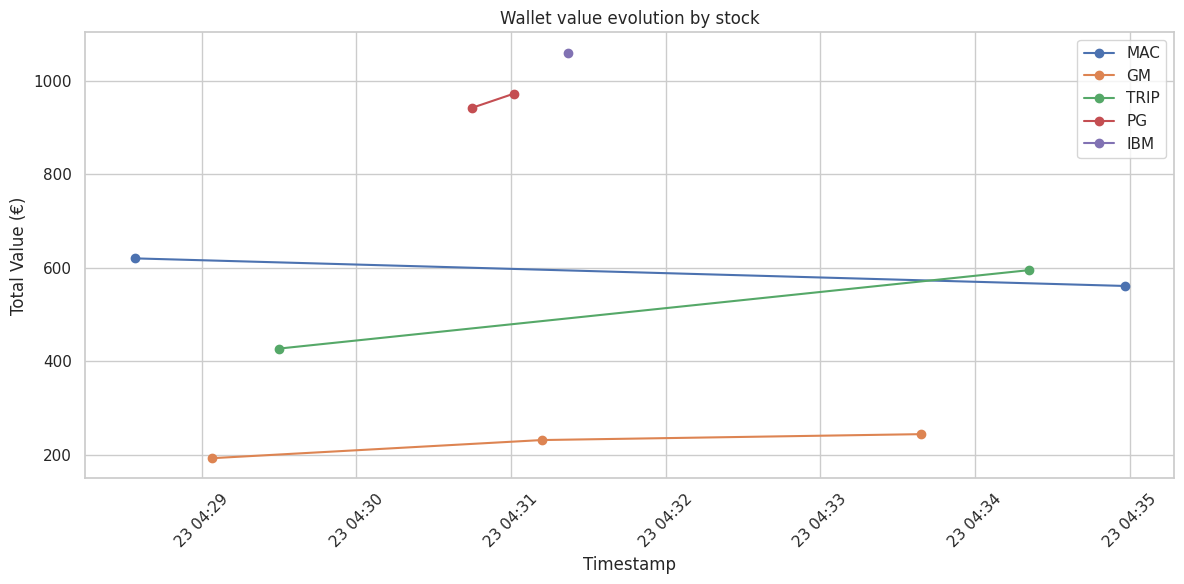

In [335]:
plt.figure(figsize=(12,6))

for stock in wallet_pdf["name"].unique():
    stock_data = wallet_pdf[wallet_pdf["name"] == stock]
    plt.plot(stock_data["timestamp"], stock_data["total_value"], marker="o", label=stock)

plt.title("Wallet value evolution by stock")
plt.xlabel("Timestamp")
plt.ylabel("Total Value (€)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 1400x600 with 0 Axes>

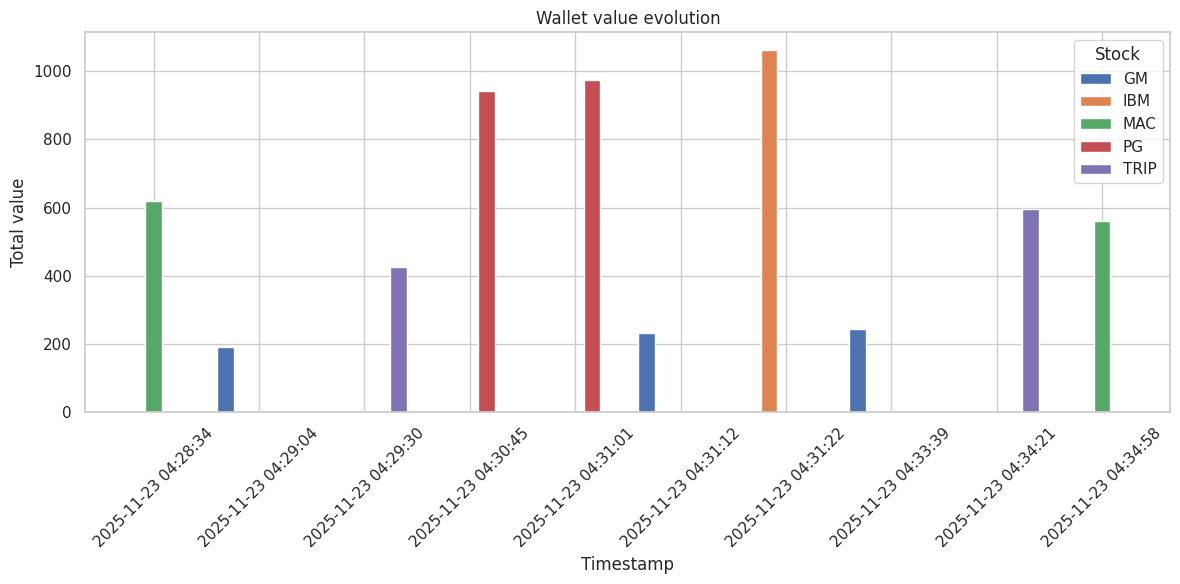

In [337]:
# Pivot the data so that each timestamp becomes a row and each stock is a column
pivot_df = wallet_pdf.pivot(index="timestamp", columns="name", values="total_value")

# Plot
plt.figure(figsize=(14,6))

pivot_df.plot(kind="bar", width=0.8)

plt.title("Wallet value evolution")
plt.xlabel("Timestamp")
plt.ylabel("Total value")
plt.xticks(rotation=45)
plt.legend(title="Stock")
plt.tight_layout()

plt.show()

_______________________________________________________________________________________________________________________________________________________________